   # GC skew analysis of E. coli K-12
   Can GC skew point to the origin of replication?

## Step 1: Download the genome and, on the next line, Download the E. coli K-12 MG1655 reference genome (NC_000913.3) from NCBI.

In [1]:
   from Bio import Entrez, SeqIO

   Entrez.email = "your@email.com"  # replace with your own address when you run this

   handle = Entrez.efetch(db="nucleotide", id="NC_000913.3",
                          rettype="fasta", retmode="text")
   with open("../data/ecoli.fasta", "w") as f:
       f.write(handle.read())
   handle.close()

   print("Download finished")

Download finished


## Step 2: Genome length and GC content and, on the next line, Load the genome and calculate its length and overall GC content.

In [2]:
record = SeqIO.read("../data/ecoli.fasta", "fasta")
print(record.id)
print(record.description)
print(len(record.seq))

NC_000913.3
NC_000913.3 Escherichia coli str. K-12 substr. MG1655, complete genome
4641652


In [3]:
record = SeqIO.read("../data/ecoli.fasta", "fasta")
seq = str(record.seq).upper()

length = len(seq)
gc = (seq.count("G") + seq.count("C")) / length * 100
print(f"Length: {length:,} bp, GC content: {gc:.1f}%")

Length: 4,641,652 bp, GC content: 50.8%


## Step 3: GC skew in windows and, on the next line, Calculate GC skew, (G-C)/(G+C), in 10,000 bp windows, then take the cumulative sum.

In [4]:
import numpy as np

window = 10_000
positions, skews = [], []
for i in range(0, length - window + 1, window):
    w = seq[i:i + window]
    g, c = w.count("G"), w.count("C")
    skews.append((g - c) / (g + c))
    positions.append(i)

cumulative = np.cumsum(skews)

## Step 4: Plot and, on the next line, Plot the cumulative skew. The minimum should mark the origin of replication and the maximum the terminus.

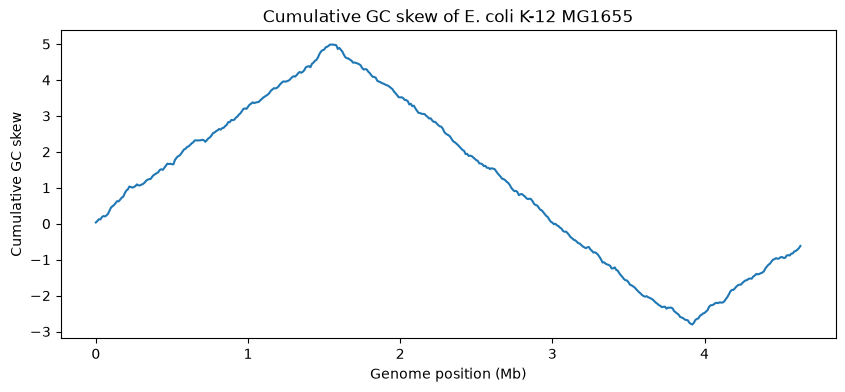

In [5]:
   import os
   import matplotlib.pyplot as plt

   os.makedirs("../results", exist_ok=True)

   fig, ax = plt.subplots(figsize=(10, 4))
   ax.plot(np.array(positions) / 1e6, cumulative)
   ax.set_xlabel("Genome position (Mb)")
   ax.set_ylabel("Cumulative GC skew")
   ax.set_title("Cumulative GC skew of E. coli K-12 MG1655")
   plt.savefig("../results/gc_skew.png", dpi=150, bbox_inches="tight")
   plt.show()

## Step 4: Plot and, on the next line, Plot the cumulative skew. The minimum should mark the origin of replication and the maximum the terminus.

In [6]:
ori_est = positions[np.argmin(cumulative)]
ter_est = positions[np.argmax(cumulative)]
print(f"Estimated origin near {ori_est/1e6:.2f} Mb, terminus near {ter_est/1e6:.2f} Mb")

Estimated origin near 3.92 Mb, terminus near 1.54 Mb


## Conclusion
The minimum of the cumulative GC skew curve is at about 3.92 Mb, which matches the annotated origin of replication (oriC) of E. coli K-12 MG1655 at roughly 3.92 Mb. The maximum is at about 1.54 Mb, close to the terminus region, which the genome map places at around 1.6-1.7 Mb. The estimate of the terminus is less precise than the origin, and both depend on the 10 kb window size.